# ДЗ 1. 
Рассмотрим сферический детектор радиусом R, заполненный
сцинтиллирующей жидкостью.
В сцинтилляторе свет от взаимодействия частиц излучается изотропно,
выход фотонов для события с энергией 1 МэВ равен Y.
Внутренняя поверхность детектора покрыта N фотоумножителями,
улавливающими свет от взаимодействия частиц. Считаем, что у
фотоумножителя плоский фотокатод радиусом r. Bероятность выбивания
хотя бы одного фотоэлектрона равна a.
Каждому фотоумножителю соответствует канал набора данных,
сохраняющий число фотоэлектронов. 

In [1]:

import numpy as np

class Detector:
    def __init__(self, R: float, N: int, r: float, a: float):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

    def dots_on_parallels(self):
 # Разместим 40 фотоумножителей на сфере по 5 параллелям по 8 точек (5*8=40) на каждой, выбрав одинаковый шаг по cos(theta), а угол phi делим на 8 равных частей
       
        n_theta = 5
        n_phi = 8

        cos_theta = 1 - 2*(np.arange(n_theta) + 0.5)/n_theta
        theta = np.arccos(cos_theta)
        phi = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

        dots = []

        for i in range(n_theta):
            for j in range(n_phi):
                x = self.R * np.sin(theta[i]) * np.cos(phi[j])
                y = self.R * np.sin(theta[i]) * np.sin(phi[j])
                z = self.R * np.cos(theta[i])

                dots.append([x, y, z])

        self.photocathode_centers = np.array(dots)


    def is_on_photocathode(self, coordinats):
        # Найдем расстояния от заданной точки до центров всех фотокатодов. Если хотя бы одно расстояние меньше радиуса фотокатода, возвращаем True

        lengths = np.linalg.norm(self.photocathode_centers - coordinats, axis=1)

        return np.any(lengths <= self.r)

detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
detector.dots_on_parallels()


In [2]:

coordinats = detector.photocathode_centers[0]
print(detector.is_on_photocathode(coordinats))

coordinats = np.array([0, 0, 2])
print(detector.is_on_photocathode(coordinats))


True
False


In [3]:
print(detector.photocathode_centers.shape)

(40, 3)


# проверка что получили ровно 40 точек и все они лежат на сфере радиуса 2, в центре первого фотокатода точно должна быть точка по построению,поэтому попадание обязательно должно быть, а вот на северном полюсе сферы \((0,0,2)\) нет фотокатода

In [4]:

def test_centers():
    centers = detector.photocathode_centers
    assert centers.shape == (40, 3)

    lengths = np.linalg.norm(centers, axis=1)
    assert np.all(abs(lengths - detector.R) < 1e-10)


In [5]:

def test_photocathode():
    coordinats = detector.photocathode_centers[0]
    assert detector.is_on_photocathode(coordinats)

    coordinats = np.array([0, 0, 2])
    assert not detector.is_on_photocathode(coordinats)


In [6]:

test_centers()
test_photocathode()
print("нет ошибок")


нет ошибок


# теперь построим сферу радиуса R и отметим на ней центры  40 фотокатодов, координаты которых выше уже нашли.

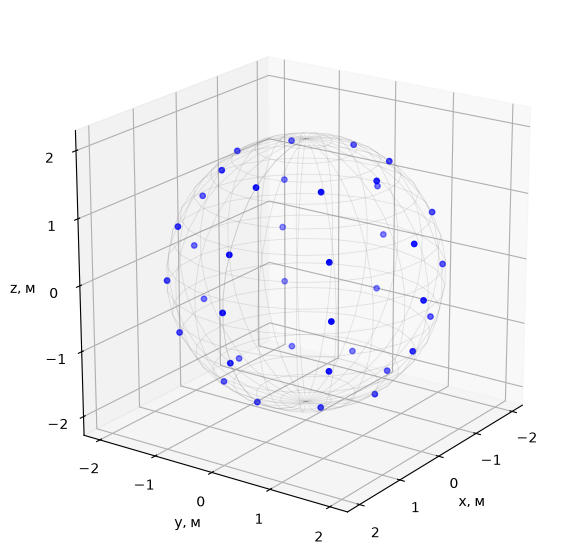

In [7]:

import matplotlib.pyplot as plt

theta = np.linspace(0, np.pi, 18)
phi = np.linspace(0, 2*np.pi, 24)
theta, phi = np.meshgrid(theta, phi)

x = detector.R * np.sin(theta) * np.cos(phi)
y = detector.R * np.sin(theta) * np.sin(phi)
z = detector.R * np.cos(theta)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_wireframe(x, y, z, color='gray', alpha=0.2, linewidth=0.6)

dots = detector.photocathode_centers
ax.scatter(dots[:, 0], dots[:, 1], dots[:, 2], color='blue', s=15)


ax.set_xlabel('x, м')
ax.set_ylabel('y, м')
ax.set_zlabel('z, м')

ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.set_zticks([-2, -1, 0, 1, 2])

ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=35)

plt.show()



# добавим еще фотокатоды как окружности радиуса r в касательных плоскостях к сфере в их центрах
# vec1 задает направление от центра сферы к центру фотокатода
# vec2 и vec3  два взаимно перпендикулярных вектора в плоскости фотокатода
# далее строим окружность радиуса detector.r перебирая угол angle

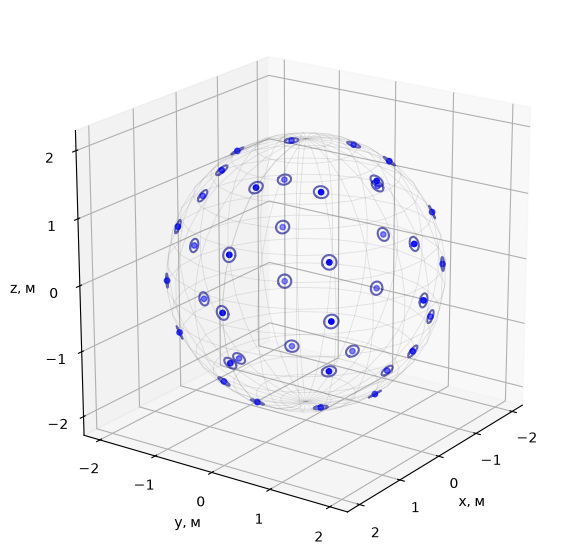

In [8]:
import matplotlib.pyplot as plt

theta = np.linspace(0, np.pi, 18)
phi = np.linspace(0, 2*np.pi, 24)
theta, phi = np.meshgrid(theta, phi)

x = detector.R * np.sin(theta) * np.cos(phi)
y = detector.R * np.sin(theta) * np.sin(phi)
z = detector.R * np.cos(theta)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_wireframe(x, y, z, color='gray', alpha=0.2, linewidth=0.6)

dots = detector.photocathode_centers
ax.scatter(dots[:, 0], dots[:, 1], dots[:, 2], color='blue', s=15)

angles = np.linspace(0, 2*np.pi, 40)

for center in detector.photocathode_centers:
    vec1 = center / np.linalg.norm(center)

    if abs(vec1[0]) < 0.9:
        vec2 = np.array([1, 0, 0])
    else:
        vec2 = np.array([0, 1, 0])

    vec2 = vec2 - np.dot(vec2, vec1) * vec1
    vec2 = vec2 / np.linalg.norm(vec2)

    vec3 = np.cross(vec1, vec2)
    vec3 = vec3 / np.linalg.norm(vec3)
    circle = []

    for angle in angles:
        point = center + detector.r * (np.cos(angle) * vec2 + np.sin(angle) * vec3)
        circle.append(point)

    circle = np.array(circle)

    ax.plot(circle[:, 0], circle[:, 1], circle[:, 2], color='darkblue', alpha=0.6)

ax.set_xlabel('x, м')
ax.set_ylabel('y, м')
ax.set_zlabel('z, м')

ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.set_zticks([-2, -1, 0, 1, 2])

ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=35)

plt.show()
